# Klasifikasi Penerima BLT Dana Desa Menggunakan Metode Naïve Bayes
**Studi Kasus: Kantor Desa Talulobutu, Kec. Tapa, Kab. Bone Bolango**

Susunan notebook mengikuti Bab IV naskah:
- **4.1** Hasil Pengumpulan Data
- **4.2** Hasil Pemodelan
  - 4.2.1 Preprocessing Data (pembersihan, pembagian data)
  - 4.2.2 Eksperimen 1 — 15 atribut (Skenario 1 dan Skenario 2)
  - 4.2.3 Eksperimen 2 — 8 atribut sosial-ekonomi (Skenario 1 dan Skenario 2)
  - 4.2.4 Perbandingan Kedua Eksperimen
  - 4.2.5 Representasi Pengetahuan
- **4.3** Visualisasi Hasil Penelitian
- Pendukung Bab V dan analisis tambahan

Skenario 1 = Gaussian Naïve Bayes (*baseline*); Skenario 2 = Tomek Links + Class Weighting + Gaussian Naïve Bayes.
Gambar tersimpan di `outputs/gambar/`, tabel di `outputs/tabel/` dan `outputs/tabel_hasil.xlsx` (nomor sesuai urutan kemunculan).

## 0. Persiapan Library dan Lokasi File

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "Dataset Desa Talulobutu Terbaru.xlsx"
MODEL_DIR = BASE_DIR / "models"
OUTPUT_DIR = BASE_DIR / "outputs"
GAMBAR_DIR, TABEL_DIR, RM_DIR = OUTPUT_DIR / "gambar", OUTPUT_DIR / "tabel", OUTPUT_DIR / "rapidminer"
for d in (MODEL_DIR, GAMBAR_DIR, TABEL_DIR, RM_DIR):
    d.mkdir(parents=True, exist_ok=True)
for f in list(GAMBAR_DIR.glob("*.png")) + list(TABEL_DIR.glob("*.csv")):
    f.unlink()   # bersihkan hasil lama agar penomoran selalu urut

sys.path.insert(0, str(BASE_DIR / "src"))
import importlib
import blt_dd
import blt_steps as steps
import blt_viz as viz
for _m in (blt_dd, viz, steps):   # muat ulang modul agar perubahan di src/ selalu terbaca
    importlib.reload(_m)
from blt_dd import (FEATURE_COLS, FEATURE_COLS_15, RANDOM_STATE, TARGET, FeatureEncoder, check_data,
                    clean_data, encode_target, evaluate, tomek_links, train_scenario)

METRIK = ["Accuracy", "Precision", "Recall", "F1-Score", "Specificity"]
DAFTAR_TABEL, _no = {}, {"t": 0, "g": 0}


def simpan(fig, nama):
    """Simpan gambar manuskrip ke outputs/gambar/gNN_<nama>.png (300 dpi)."""
    _no["g"] += 1
    fig.savefig(GAMBAR_DIR / f"g{_no['g']:02d}_{nama}.png", dpi=300, bbox_inches="tight")
    plt.show()


def tabel(df, nama, judul, desimal=4):
    """Simpan tabel (CSV + Excel) dengan nomor urut, lalu tampilkan dengan format angka Indonesia."""
    _no["t"] += 1
    kode = f"t{_no['t']:02d}_{nama}"
    df = df.copy()
    num = df.select_dtypes("number").columns
    df[num] = df[num].round(desimal)
    if desimal == 0:
        df[num] = df[num].astype("Int64")
    DAFTAR_TABEL[kode] = (judul, df)
    df.to_csv(TABEL_DIR / f"{kode}.csv", index=False, encoding="utf-8-sig")
    display(df.style.hide(axis="index").set_caption(f"[{kode}] {judul}")
              .format(precision=desimal, decimal=",", thousands=".")
              .set_table_styles([{"selector": "caption",
                                  "props": "caption-side: top; font-weight: bold; text-align: left;"}]))


print("Data :", DATA_PATH, "| ada:", DATA_PATH.exists())

Data : C:\Users\FIQRI\Documents\JOKISKRIPSI\CS_1_data-mining\blt-dd-naive-bayes\data\Dataset Desa Talulobutu Terbaru.xlsx | ada: True


## 4.1 Hasil Pengumpulan Data

In [2]:
df_raw = pd.read_excel(DATA_PATH)
df = clean_data(df_raw)
print("Jumlah data:", df_raw.shape[0], "KK | jumlah kolom:", df_raw.shape[1])
tabel(steps.cuplikan_dataset(df_raw), "cuplikan_dataset", "Cuplikan Dataset Hasil Pengumpulan (10 data pertama)", desimal=0)

Jumlah data: 392 KK | jumlah kolom: 21


No,NIK,Nama,Usia,Jenis Kelamin,Alamat,Pekerjaan,Pendidikan terakhir,Status Pernikahan,Tanggungan Keluarga,Kehilangan Mata Pencaharian,Status Tempat Tinggal,DTKS/Non DTKS,Menerima Bantuan Lain,Kepala Keluarga Miskin,Anggota Keluarga yang sakit menahun/Kronis,anggota keluarga disabilitas,Kepala keluarga tunggal Lanjut Usia,perempuan kepala keluarga miskin,Status Kelayakan,Status Penerima BLT-DD,Status Kelayakan Verifikasi
1,75030**********,S***,41,L,Dusun I,Buruh Harian Lepas,SMA,Kawin,3,Tidak,Milik Sendiri,DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak,Tidak,Layak
2,75030**********,I***,78,L,Dusun I,Tidak Bekerja,SD,Duda,0,Tidak,Menumpang,DTKS,Ya,Ya,Ya,Tidak,Ya,Tidak,Tidak Layak,Tidak,Layak
3,75030**********,R***,63,L,Dusun I,Petani,SD,Kawin,0,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Ya,Tidak,Tidak Layak,Tidak,Layak
4,75031**********,J***,60,L,Dusun I,PNS,S1,Kawin,2,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak,Tidak,Tidak Layak
5,75030**********,A***,81,L,Dusun I,Tidak Bekerja,Tidak Tamat SD,Duda,0,Tidak,Milik Sendiri,Non DTKS,Tidak,Ya,Tidak,Tidak,Ya,Tidak,Tidak Layak,Tidak,Layak
6,75030**********,R***,46,L,Dusun I,Pedagang,SD,Kawin,2,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak,Tidak,Tidak Layak
7,75030**********,S***,51,P,Dusun I,IRT,SMA,Kawin,4,Ya,Milik Sendiri,Non DTKS,Tidak,Ya,Tidak,Tidak,Tidak,Ya,Tidak Layak,Tidak,Layak
8,75030**********,S***,33,P,Dusun I,IRT,SD,Kawin,3,Tidak,Milik Sendiri,DTKS,Tidak,Ya,Tidak,Tidak,Tidak,Tidak,Tidak Layak,Tidak,Layak
9,750301**********,I***,44,L,Dusun I,Pedagang,SD,Kawin,1,Tidak,Milik Sendiri,DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak,Tidak,Layak
10,75030**********,Y***,58,L,Dusun I,Petani,Tidak Tamat SD,Kawin,2,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak,Tidak,Tidak Layak


Atribut Status,Layak / Ya,Tidak Layak / Tidak,Rasio,Keterangan
Status Kelayakan Verifikasi,"142 (36,22%)","250 (63,78%)","1 : 1,76",Lolos verifikasi kriteria (target penelitian)
Status Kelayakan,"27 (6,89%)","365 (93,11%)","1 : 13,52",Ditetapkan sebagai penerima
Status Penerima BLT-DD,"27 (6,89%)","365 (93,11%)","1 : 13,52",Menerima BLT-DD


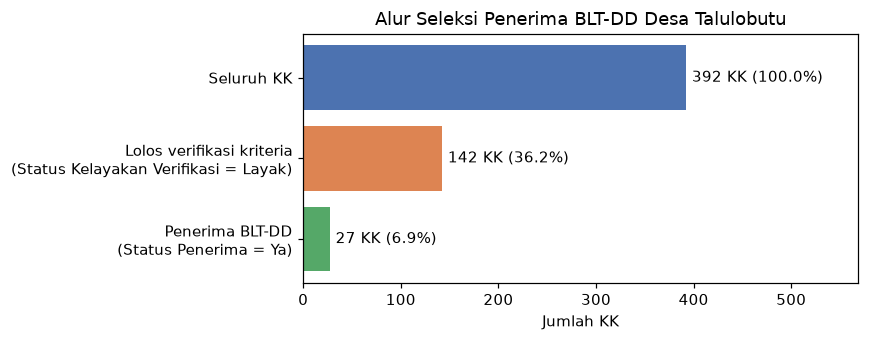

Status Kelayakan,Status Penerima BLT-DD,Layak,Tidak Layak,Total
Layak,Ya,27,0,27
Tidak Layak,Tidak,115,250,365
Total,,142,250,392


In [3]:
tabel(viz.tabel_atribut_status(df), "atribut_status", "Perbandingan Atribut Status pada Dataset")
fig, tabel_status = viz.fig_alur_seleksi(df)
simpan(fig, "alur_seleksi")
tabel(tabel_status, "hubungan_atribut_status", "Hubungan Ketiga Atribut Status", desimal=0)

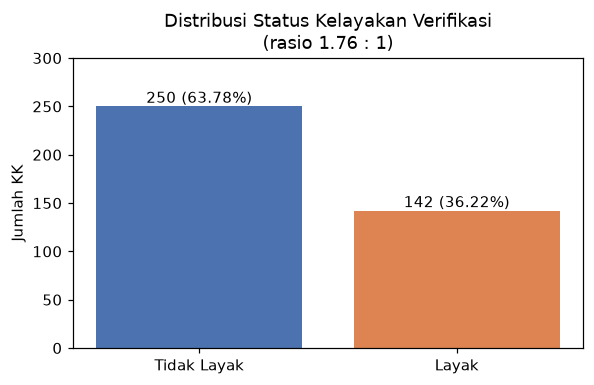

Kelas,Jumlah KK,Persentase (%)
Layak,142,"36,22"
Tidak Layak,250,"63,78"
Total,392,"100,00"


In [4]:
simpan(viz.fig_distribusi_kelas(df), "distribusi_kelas")
tabel(viz.tabel_distribusi_kelas(df), "distribusi_kelas", "Distribusi Kelas Status Kelayakan Verifikasi", desimal=2)

## 4.2 Hasil Pemodelan
### 4.2.1 Preprocessing Data
**a. Pembersihan data**

In [5]:
tabel(steps.tabel_pembersihan(df_raw), "hasil_pembersihan", "Hasil Pembersihan Data", desimal=0)
tabel(check_data(df).reset_index(names="Atribut"), "pemeriksaan_atribut",
      "Pemeriksaan Tipe, Nilai Kosong, dan Nilai Unik per Atribut", desimal=0)

Pemeriksaan,Hasil,Tindakan
Jumlah data awal,392,-
Baris dengan nilai kosong (missing value),0,Tidak ada yang dihapus
NIK ganda,0,Tidak ada yang dihapus
Baris duplikat,0,Tidak ada yang dihapus
"Penyeragaman teks (spasi, penulisan Diploma)",-,Dirapikan
Jumlah data akhir,392,-


Atribut,Tipe,Nilai Kosong,Jumlah Nilai Unik
NIK,str,0,392
Nama,str,0,392
Usia,int64,0,64
Jenis Kelamin,str,0,2
Alamat,str,0,3
Pekerjaan,str,0,21
Pendidikan terakhir,str,0,7
Status Pernikahan,str,0,5
Tanggungan Keluarga,int64,0,7
Kehilangan Mata Pencaharian,str,0,2


**b. Pembagian data** — 80% training : 20% testing, *stratified*, random_state = 42. Pembagian yang sama dipakai pada kedua eksperimen.

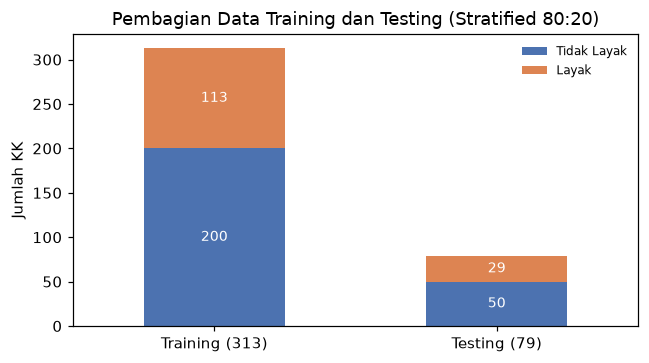

Data,Layak,Tidak Layak,Jumlah
Data training (80%),113,200,313
Data testing (20%),29,50,79
Total,142,250,392


In [6]:
E15 = steps.jalankan_eksperimen(df, FEATURE_COLS_15)
E8 = steps.jalankan_eksperimen(df, FEATURE_COLS)
assert (E15["no_test"] == E8["no_test"]).all()   # data testing kedua eksperimen identik
simpan(viz.fig_pembagian_data(E8["y_train"], E8["y_test"]), "pembagian_data")
tabel(E8["t_pembagian"], "pembagian_data", "Pembagian Data Training dan Testing", desimal=0)

### 4.2.2 Eksperimen 1 — 15 Atribut
**a. Seleksi atribut**

In [7]:
tabel(E15["t_seleksi"], "seleksi_e1", "Hasil Seleksi Atribut Eksperimen 1")
tabel(E15["t_cuplikan_seleksi"], "cuplikan_seleksi_e1", "Cuplikan Data Hasil Seleksi Eksperimen 1 (10 data pertama)", desimal=0)

Atribut,Keterangan,Alasan
NIK,Dikeluarkan,"Identitas, tidak bersifat prediktif"
Nama,Dikeluarkan,"Identitas, tidak bersifat prediktif"
Alamat,Dikeluarkan,"Identitas, tidak bersifat prediktif"
Status Kelayakan,Dikeluarkan,Keputusan administratif penerima akhir (berpotensi kebocoran data)
Status Penerima BLT-DD,Dikeluarkan,Keputusan administratif penerima akhir (berpotensi kebocoran data)
Usia,Atribut input,Kondisi sosial-ekonomi
Jenis Kelamin,Atribut input,Kondisi sosial-ekonomi
Pekerjaan,Atribut input,Kondisi sosial-ekonomi
Pendidikan terakhir,Atribut input,Kondisi sosial-ekonomi
Status Pernikahan,Atribut input,Kondisi sosial-ekonomi


No,Usia,Jenis Kelamin,Pekerjaan,Pendidikan terakhir,Status Pernikahan,Tanggungan Keluarga,Kehilangan Mata Pencaharian,Status Tempat Tinggal,DTKS/Non DTKS,Menerima Bantuan Lain,Kepala Keluarga Miskin,Anggota Keluarga yang sakit menahun/Kronis,anggota keluarga disabilitas,Kepala keluarga tunggal Lanjut Usia,perempuan kepala keluarga miskin,Status Kelayakan Verifikasi
1,41,L,Buruh Harian Lepas,SMA,Kawin,3,Tidak,Milik Sendiri,DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Layak
2,78,L,Tidak Bekerja,SD,Duda,0,Tidak,Menumpang,DTKS,Ya,Ya,Ya,Tidak,Ya,Tidak,Layak
3,63,L,Petani,SD,Kawin,0,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Ya,Tidak,Layak
4,60,L,PNS,S1,Kawin,2,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak
5,81,L,Tidak Bekerja,Tidak Tamat SD,Duda,0,Tidak,Milik Sendiri,Non DTKS,Tidak,Ya,Tidak,Tidak,Ya,Tidak,Layak
6,46,L,Pedagang,SD,Kawin,2,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak
7,51,P,IRT,SMA,Kawin,4,Ya,Milik Sendiri,Non DTKS,Tidak,Ya,Tidak,Tidak,Tidak,Ya,Layak
8,33,P,IRT,SD,Kawin,3,Tidak,Milik Sendiri,DTKS,Tidak,Ya,Tidak,Tidak,Tidak,Tidak,Layak
9,44,L,Pedagang,SD,Kawin,1,Tidak,Milik Sendiri,DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Layak
10,58,L,Petani,Tidak Tamat SD,Kawin,2,Tidak,Milik Sendiri,Non DTKS,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak Layak


**b. Transformasi data** (aturan transformasi ditentukan dari data training, lalu diterapkan ke data testing)

In [8]:
print("Jumlah kolom setelah transformasi:", E15["X_train"].shape[1])
tabel(E15["t_aturan"], "aturan_transformasi_e1", "Aturan Transformasi Data Eksperimen 1")
tabel(E15["t_cuplikan_transformasi"], "cuplikan_transformasi_e1",
      "Cuplikan Data Training Hasil Transformasi Eksperimen 1 (10 data pertama)", desimal=0)

Jumlah kolom setelah transformasi: 31


Atribut,Jenis,Nilai asli,Hasil transformasi
Usia,Numerik,angka,nilai tetap
Jenis Kelamin,Biner,P / L,"P = 1, lainnya = 0"
Pekerjaan,Nominal (one-hot),"Buruh Harian Lepas, Honorer, IRT, Karyawan Swasta, PNS, Pedagang, Pensiunan, Petani, Tidak Bekerja, Transportasi, Tukang, Wiraswasta, Lainnya",13 kolom biner (Pekerjaan_); kategori < 5 data = Lainnya
Pendidikan terakhir,Ordinal,"Tidak Tamat SD, SD, SMP, SMA, Diploma, S1, S2","Tidak Tamat SD=0, SD=1, SMP=2, SMA=3, Diploma=4, S1=5, S2=6"
Status Pernikahan,Nominal (one-hot),"Belum Kawin, Duda, Janda, Kawin, Lainnya",5 kolom biner (Status Pernikahan_); kategori < 5 data = Lainnya
Tanggungan Keluarga,Numerik,angka,nilai tetap
Kehilangan Mata Pencaharian,Biner,Ya / Tidak,"Ya = 1, lainnya = 0"
Status Tempat Tinggal,Biner,Menumpang / Milik Sendiri,"Menumpang = 1, lainnya = 0"
DTKS/Non DTKS,Biner,DTKS / Non DTKS,"DTKS = 1, lainnya = 0"
Menerima Bantuan Lain,Biner,Ya / Tidak,"Ya = 1, lainnya = 0"


No,Usia,Jenis Kelamin,Pekerjaan_Buruh Harian Lepas,Pekerjaan_Honorer,Pekerjaan_IRT,Pekerjaan_Karyawan Swasta,Pekerjaan_PNS,Pekerjaan_Pedagang,Pekerjaan_Pensiunan,Pekerjaan_Petani,Pekerjaan_Tidak Bekerja,Pekerjaan_Transportasi,Pekerjaan_Tukang,Pekerjaan_Wiraswasta,Pekerjaan_Lainnya,Pendidikan terakhir,Status Pernikahan_Belum Kawin,Status Pernikahan_Duda,Status Pernikahan_Janda,Status Pernikahan_Kawin,Status Pernikahan_Lainnya,Tanggungan Keluarga,Kehilangan Mata Pencaharian,Status Tempat Tinggal,DTKS/Non DTKS,Menerima Bantuan Lain,Kepala Keluarga Miskin,Anggota Keluarga yang sakit menahun/Kronis,anggota keluarga disabilitas,Kepala keluarga tunggal Lanjut Usia,perempuan kepala keluarga miskin
1,71,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0
2,37,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,2,0,0,1,1,1,0,0,0,1
3,27,0,0,0,0,0,0,0,0,0,0,0,0,1,0,5,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0
4,54,0,0,0,0,0,0,0,0,0,0,0,0,1,0,5,0,0,0,1,0,5,0,0,0,0,0,0,0,0,0
5,35,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
6,60,0,0,0,0,0,1,0,0,0,0,0,0,0,0,5,0,0,0,1,0,2,0,0,0,0,0,0,0,0,0
7,51,1,0,0,1,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,4,1,0,0,0,1,0,0,0,1
8,51,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0
9,30,0,0,0,0,0,0,0,0,0,0,0,0,0,1,5,0,0,0,1,0,2,0,1,0,0,0,0,0,0,0
10,69,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,0,0,1


**c. Skenario 1 — Gaussian Naïve Bayes**: Langkah 1 prior $P(C)$, Langkah 2 mean dan varians, Langkah 3 posterior dan prediksi

In [9]:
tabel(E15["t_prior1"], "prior_s1_e1", "Probabilitas Prior Skenario 1 Eksperimen 1")
tabel(E15["t_param1"], "parameter_s1_e1", "Parameter Gaussian (Mean dan Varians) Skenario 1 Eksperimen 1")
E15["t_pred1"].to_csv(TABEL_DIR / "lampiran_prediksi_s1_e1.csv", index=False, encoding="utf-8-sig")
tabel(E15["t_pred1"].head(10), "prediksi_s1_e1", "Cuplikan Hasil Prediksi Skenario 1 Eksperimen 1 (10 data testing)")

Kelas,Jumlah data,Bobot per data,Total bobot,Prior P(C)
Tidak Layak,200,"1,0000","200,0000","0,6390"
Layak,113,"1,0000","113,0000","0,3610"


Atribut,Mean Tidak Layak,Varians Tidak Layak,Mean Layak,Varians Layak
Usia,"46,8000","170,1700","56,3274","233,9547"
Jenis Kelamin,"0,1100","0,0979","0,4159","0,2429"
Pekerjaan_Buruh Harian Lepas,"0,1050","0,0940","0,1150","0,1018"
Pekerjaan_Honorer,"0,0400","0,0384","0,0088","0,0088"
Pekerjaan_IRT,"0,0200","0,0196","0,2389","0,1818"
Pekerjaan_Karyawan Swasta,"0,1050","0,0940","0,0088","0,0088"
Pekerjaan_PNS,"0,1350","0,1168","0,0088","0,0088"
Pekerjaan_Pedagang,"0,0300","0,0291","0,0442","0,0423"
Pekerjaan_Pensiunan,"0,0950","0,0860","0,0088","0,0088"
Pekerjaan_Petani,"0,0400","0,0384","0,0885","0,0807"


No. data,Aktual,P(Tidak Layak | X),P(Layak | X),Prediksi,Keterangan
15,Layak,"0,0000","1,0000",Layak,Benar
82,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
320,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
101,Layak,"0,0000","1,0000",Layak,Benar
342,Layak,"0,0000","1,0000",Layak,Benar
325,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
134,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
338,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
138,Layak,"0,0000","1,0000",Layak,Benar
40,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar


**d. Skenario 2 — Tomek Links + Class Weighting + Gaussian Naïve Bayes**

Pasangan,No. data Tidak Layak,No. data Layak,Jarak Euclidean,Data dihapus
1,257,104,"3,2173",No. 257 (Tidak Layak)
2,58,326,"2,8193",No. 58 (Tidak Layak)
3,126,130,"2,9519",No. 126 (Tidak Layak)


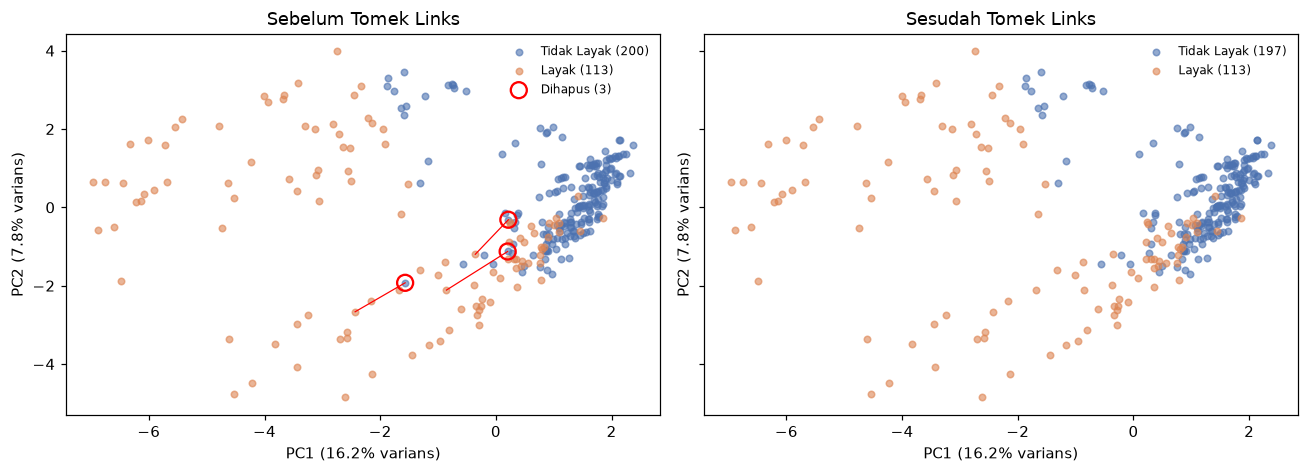

Kelas,Sebelum Tomek Links,Sesudah Tomek Links,Dihapus
Tidak Layak,200,197,3
Layak,113,113,0
Total,313,310,3


In [10]:
tabel(E15["t_tomek"], "pasangan_tomek_e1", "Pasangan Tomek Link pada Data Training Eksperimen 1")
simpan(viz.fig_tomek_links(E15["Xs"], E15["y_train"], E15["idx_hapus"], E15["pasangan"], RANDOM_STATE), "tomek_links_e1")
tabel(E15["t_hasil_tomek"], "hasil_tomek_e1", "Jumlah Data Training Sebelum dan Sesudah Tomek Links Eksperimen 1", desimal=0)

Kelas,Jumlah data,Bobot per data,Total bobot,Prior P(C)
Tidak Layak,197,"0,7868","155,0000","0,5000"
Layak,113,"1,3717","155,0000","0,5000"


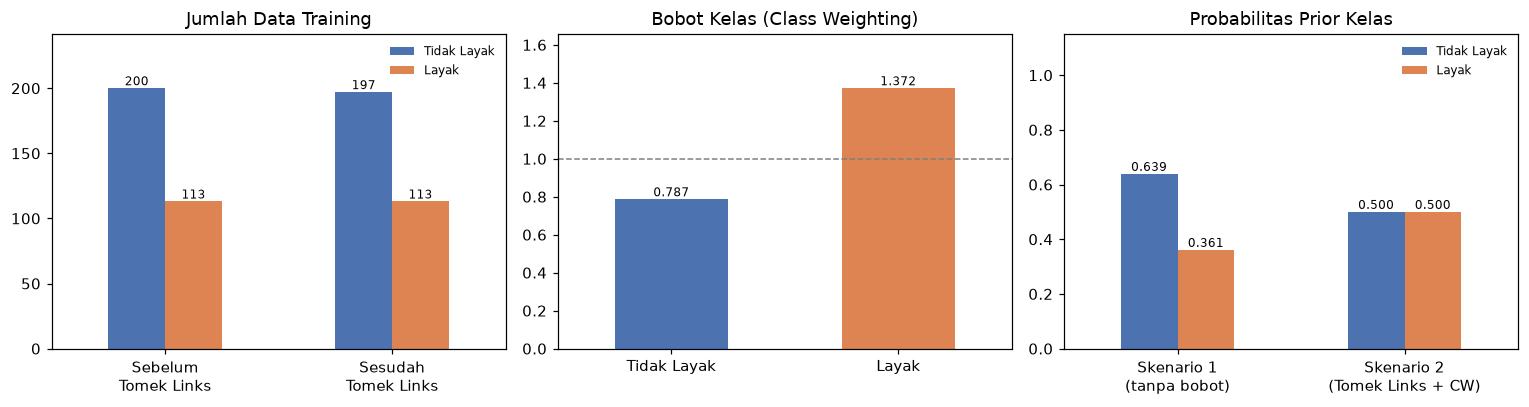

Atribut,Mean Tidak Layak,Varians Tidak Layak,Mean Layak,Varians Layak
Usia,"46,5635","166,7434","56,3274","233,9547"
Jenis Kelamin,"0,1117","0,0992","0,4159","0,2429"
Pekerjaan_Buruh Harian Lepas,"0,1066","0,0952","0,1150","0,1018"
Pekerjaan_Honorer,"0,0406","0,0390","0,0088","0,0088"
Pekerjaan_IRT,"0,0203","0,0199","0,2389","0,1818"
Pekerjaan_Karyawan Swasta,"0,1066","0,0952","0,0088","0,0088"
Pekerjaan_PNS,"0,1371","0,1183","0,0088","0,0088"
Pekerjaan_Pedagang,"0,0305","0,0295","0,0442","0,0423"
Pekerjaan_Pensiunan,"0,0964","0,0871","0,0088","0,0088"
Pekerjaan_Petani,"0,0406","0,0390","0,0885","0,0807"


No. data,Aktual,P(Tidak Layak | X),P(Layak | X),Prediksi,Keterangan
15,Layak,"0,0000","1,0000",Layak,Benar
82,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
320,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
101,Layak,"0,0000","1,0000",Layak,Benar
342,Layak,"0,0000","1,0000",Layak,Benar
325,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
134,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
338,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
138,Layak,"0,0000","1,0000",Layak,Benar
40,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar


In [11]:
tabel(E15["t_prior2"], "bobot_prior_s2_e1", "Bobot Kelas dan Probabilitas Prior Skenario 2 Eksperimen 1")
simpan(viz.fig_class_weighting(E15["y_train"], E15["y_tl"], E15["bobot"], E15["prior1"], E15["prior2"])[0],
       "class_weighting_e1")
tabel(E15["t_param2"], "parameter_s2_e1", "Parameter Gaussian Berbobot Skenario 2 Eksperimen 1")
E15["t_pred2"].to_csv(TABEL_DIR / "lampiran_prediksi_s2_e1.csv", index=False, encoding="utf-8-sig")
tabel(E15["t_pred2"].head(10), "prediksi_s2_e1", "Cuplikan Hasil Prediksi Skenario 2 Eksperimen 1 (10 data testing)")

**e. Evaluasi (confusion matrix)**

Aktual \ Prediksi,Prediksi Tidak Layak,Prediksi Layak
Tidak Layak,50,0
Layak,0,29


Aktual \ Prediksi,Prediksi Tidak Layak,Prediksi Layak
Tidak Layak,50,0
Layak,0,29


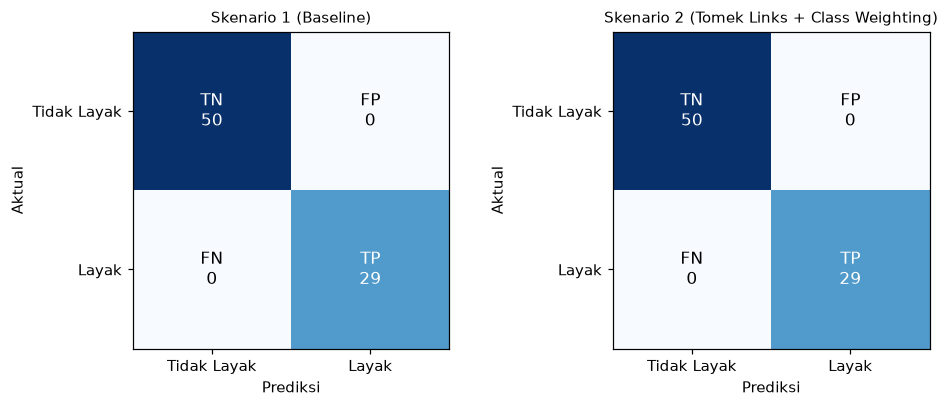

Metrik,Rumus,Substitusi,Hasil
Accuracy,(TP + TN) / (TP + TN + FP + FN),(29 + 50) / (29 + 50 + 0 + 0),"1,0000"
Precision,TP / (TP + FP),29 / (29 + 0),"1,0000"
Recall,TP / (TP + FN),29 / (29 + 0),"1,0000"
F1-Score,2 × (Precision × Recall) / (Precision + Recall),"2 × (1,0000 × 1,0000) / (1,0000 + 1,0000)","1,0000"
Specificity,TN / (TN + FP),50 / (50 + 0),"1,0000"


Metrik,Rumus,Substitusi,Hasil
Accuracy,(TP + TN) / (TP + TN + FP + FN),(29 + 50) / (29 + 50 + 0 + 0),"1,0000"
Precision,TP / (TP + FP),29 / (29 + 0),"1,0000"
Recall,TP / (TP + FN),29 / (29 + 0),"1,0000"
F1-Score,2 × (Precision × Recall) / (Precision + Recall),"2 × (1,0000 × 1,0000) / (1,0000 + 1,0000)","1,0000"
Specificity,TN / (TN + FP),50 / (50 + 0),"1,0000"


In [12]:
tabel(E15["t_cm1"], "cm_s1_e1", "Confusion Matrix Skenario 1 Eksperimen 1", desimal=0)
tabel(E15["t_cm2"], "cm_s2_e1", "Confusion Matrix Skenario 2 Eksperimen 1", desimal=0)
simpan(viz.fig_confusion_pair(E15["hasil_s1"], E15["hasil_s2"]), "confusion_matrix_e1")
tabel(E15["t_metrik1"], "metrik_s1_e1", "Perhitungan Metrik Evaluasi Skenario 1 Eksperimen 1")
tabel(E15["t_metrik2"], "metrik_s2_e1", "Perhitungan Metrik Evaluasi Skenario 2 Eksperimen 1")

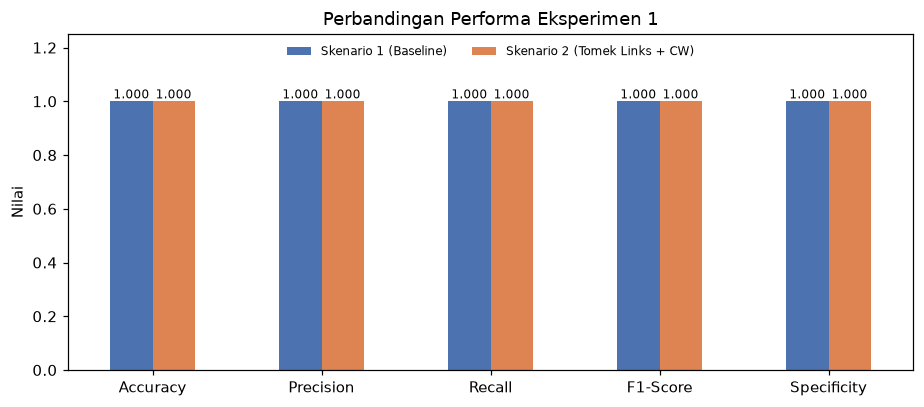

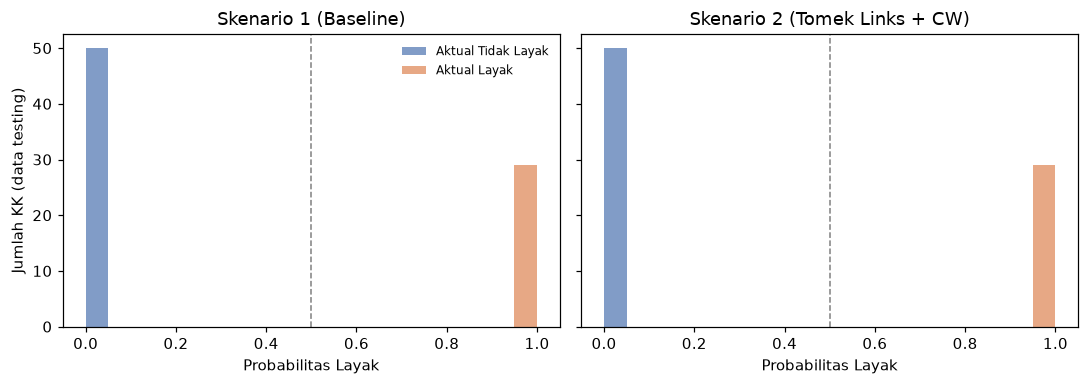

Skenario,TP,TN,FP,FN,Accuracy,Precision,Recall,F1-Score,Specificity
Skenario 1 (Baseline),29,50,0,0,"1,0000","1,0000","1,0000","1,0000","1,0000"
Skenario 2 (Tomek Links + CW),29,50,0,0,"1,0000","1,0000","1,0000","1,0000","1,0000"


In [13]:
perb = pd.DataFrame({"Skenario 1 (Baseline)": E15["hasil_s1"], "Skenario 2 (Tomek Links + CW)": E15["hasil_s2"]}).T
simpan(viz.fig_perbandingan_metrik(perb, "Perbandingan Performa Eksperimen 1"), "perbandingan_e1")
simpan(viz.fig_probabilitas(E15["y_test"], E15["proba1"], E15["proba2"]), "probabilitas_e1")
tabel(E15["t_perbandingan"], "perbandingan_e1", "Perbandingan Performa Skenario 1 dan Skenario 2 Eksperimen 1")

**f. Analisis hasil Eksperimen 1** — mengapa akurasi mencapai 100%

Aturan 7 kriteria,Layak,Tidak Layak,Total
Minimal 1 kriteria Ya/DTKS,142,0,142
Tidak ada kriteria,0,250,250
Total,142,250,392


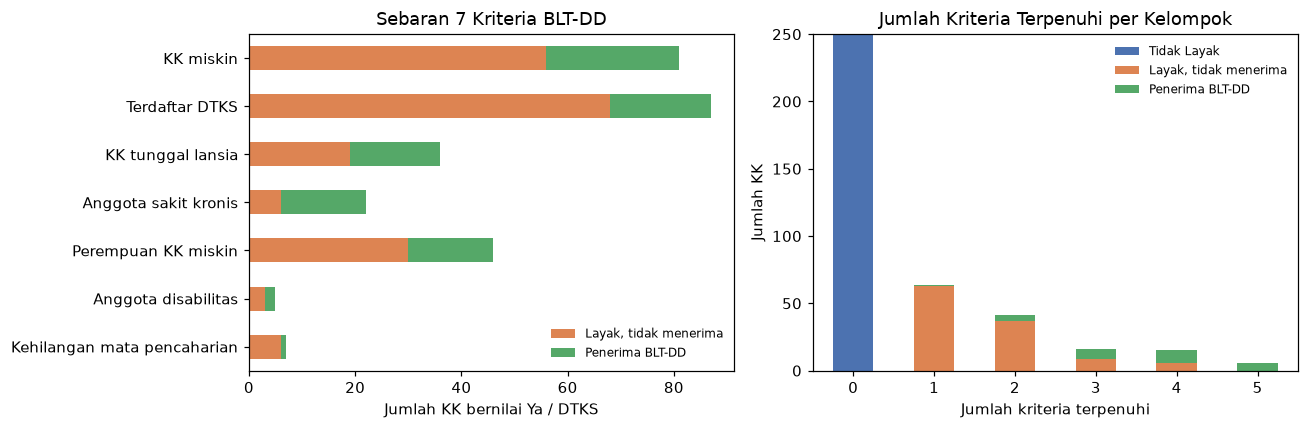

Jumlah kriteria terpenuhi,Tidak Layak,"Layak, tidak menerima",Penerima BLT-DD,Total
0,250,0,0,250
1,0,63,1,64
2,0,37,4,41
3,0,9,7,16
4,0,6,9,15
5,0,0,6,6
Total,250,115,27,392


Metode,TP,TN,FP,FN,Accuracy,Precision,Recall,F1-Score
Aturan IF-ELSE (minimal 1 kriteria = Layak),29,50,0,0,"1,0000","1,0000","1,0000","1,0000"
Gaussian NB Skenario 1 (15 atribut),29,50,0,0,"1,0000","1,0000","1,0000","1,0000"
Gaussian NB Skenario 2 (15 atribut),29,50,0,0,"1,0000","1,0000","1,0000","1,0000"


In [14]:
tabel(viz.tabel_aturan_kriteria(df), "aturan_kriteria", "Pemenuhan 7 Kriteria terhadap Status Kelayakan Verifikasi", desimal=0)
fig, tabel_jumlah_kriteria = viz.fig_kriteria(df)
simpan(fig, "kriteria_per_kelompok")
tabel(tabel_jumlah_kriteria, "jumlah_kriteria", "Jumlah Kriteria Terpenuhi per Kelompok", desimal=0)
tabel(steps.evaluasi_aturan_if(df, E15), "aturan_if_else",
      "Perbandingan Aturan IF-ELSE dan Gaussian Naïve Bayes Eksperimen 1 pada Data Testing yang Sama")

In [15]:
M15 = steps.perhitungan_manual(E15)
print(f"Data testing urutan ke-{M15['urutan'] + 1} (No. data {M15['no_data']}) | aktual: {M15['aktual']} | prediksi: {M15['prediksi']}")
tabel(M15["t_validasi"], "posterior_manual_e1", "Posterior Perhitungan Manual Eksperimen 1 (Skenario 1)")

Data testing urutan ke-1 (No. data 15) | aktual: Layak | prediksi: Layak


Kelas,ln P(C),Σ ln P(x|C),ln P(C) + Σ ln P(x|C),Posterior (manual),Posterior (sistem)
Tidak Layak,"-0,4479","-4.669.853,7353","-4.669.854,1832","0,0000","0,0000"
Layak,"-1,0188","-9,8488","-10,8676","1,0000","1,0000"


### 4.2.3 Eksperimen 2 — 8 Atribut Sosial-Ekonomi
**a. Seleksi atribut**

In [16]:
tabel(E8["t_seleksi"], "seleksi_e2", "Hasil Seleksi Atribut Eksperimen 2")
tabel(E8["t_cuplikan_seleksi"], "cuplikan_seleksi_e2", "Cuplikan Data Hasil Seleksi Eksperimen 2 (10 data pertama)", desimal=0)

Atribut,Keterangan,Alasan
NIK,Dikeluarkan,"Identitas, tidak bersifat prediktif"
Nama,Dikeluarkan,"Identitas, tidak bersifat prediktif"
Alamat,Dikeluarkan,"Identitas, tidak bersifat prediktif"
Status Kelayakan,Dikeluarkan,Keputusan administratif penerima akhir (berpotensi kebocoran data)
Status Penerima BLT-DD,Dikeluarkan,Keputusan administratif penerima akhir (berpotensi kebocoran data)
DTKS/Non DTKS,Dikeluarkan,Kriteria BLT-DD penentu label (minimal 1 kriteria = Layak)
Kepala Keluarga Miskin,Dikeluarkan,Kriteria BLT-DD penentu label (minimal 1 kriteria = Layak)
perempuan kepala keluarga miskin,Dikeluarkan,Kriteria BLT-DD penentu label (minimal 1 kriteria = Layak)
Kepala keluarga tunggal Lanjut Usia,Dikeluarkan,Kriteria BLT-DD penentu label (minimal 1 kriteria = Layak)
Kehilangan Mata Pencaharian,Dikeluarkan,Kriteria BLT-DD penentu label (minimal 1 kriteria = Layak)


No,Usia,Jenis Kelamin,Pekerjaan,Pendidikan terakhir,Status Pernikahan,Tanggungan Keluarga,Status Tempat Tinggal,Menerima Bantuan Lain,Status Kelayakan Verifikasi
1,41,L,Buruh Harian Lepas,SMA,Kawin,3,Milik Sendiri,Tidak,Layak
2,78,L,Tidak Bekerja,SD,Duda,0,Menumpang,Ya,Layak
3,63,L,Petani,SD,Kawin,0,Milik Sendiri,Tidak,Layak
4,60,L,PNS,S1,Kawin,2,Milik Sendiri,Tidak,Tidak Layak
5,81,L,Tidak Bekerja,Tidak Tamat SD,Duda,0,Milik Sendiri,Tidak,Layak
6,46,L,Pedagang,SD,Kawin,2,Milik Sendiri,Tidak,Tidak Layak
7,51,P,IRT,SMA,Kawin,4,Milik Sendiri,Tidak,Layak
8,33,P,IRT,SD,Kawin,3,Milik Sendiri,Tidak,Layak
9,44,L,Pedagang,SD,Kawin,1,Milik Sendiri,Tidak,Layak
10,58,L,Petani,Tidak Tamat SD,Kawin,2,Milik Sendiri,Tidak,Tidak Layak


**b. Transformasi data** (aturan transformasi ditentukan dari data training, lalu diterapkan ke data testing)

In [17]:
print("Jumlah kolom setelah transformasi:", E8["X_train"].shape[1])
tabel(E8["t_aturan"], "aturan_transformasi_e2", "Aturan Transformasi Data Eksperimen 2")
tabel(E8["t_cuplikan_transformasi"], "cuplikan_transformasi_e2",
      "Cuplikan Data Training Hasil Transformasi Eksperimen 2 (10 data pertama)", desimal=0)

Jumlah kolom setelah transformasi: 24


Atribut,Jenis,Nilai asli,Hasil transformasi
Usia,Numerik,angka,nilai tetap
Jenis Kelamin,Biner,P / L,"P = 1, lainnya = 0"
Pekerjaan,Nominal (one-hot),"Buruh Harian Lepas, Honorer, IRT, Karyawan Swasta, PNS, Pedagang, Pensiunan, Petani, Tidak Bekerja, Transportasi, Tukang, Wiraswasta, Lainnya",13 kolom biner (Pekerjaan_); kategori < 5 data = Lainnya
Pendidikan terakhir,Ordinal,"Tidak Tamat SD, SD, SMP, SMA, Diploma, S1, S2","Tidak Tamat SD=0, SD=1, SMP=2, SMA=3, Diploma=4, S1=5, S2=6"
Status Pernikahan,Nominal (one-hot),"Belum Kawin, Duda, Janda, Kawin, Lainnya",5 kolom biner (Status Pernikahan_); kategori < 5 data = Lainnya
Tanggungan Keluarga,Numerik,angka,nilai tetap
Status Tempat Tinggal,Biner,Menumpang / Milik Sendiri,"Menumpang = 1, lainnya = 0"
Menerima Bantuan Lain,Biner,Ya / Tidak,"Ya = 1, lainnya = 0"


No,Usia,Jenis Kelamin,Pekerjaan_Buruh Harian Lepas,Pekerjaan_Honorer,Pekerjaan_IRT,Pekerjaan_Karyawan Swasta,Pekerjaan_PNS,Pekerjaan_Pedagang,Pekerjaan_Pensiunan,Pekerjaan_Petani,Pekerjaan_Tidak Bekerja,Pekerjaan_Transportasi,Pekerjaan_Tukang,Pekerjaan_Wiraswasta,Pekerjaan_Lainnya,Pendidikan terakhir,Status Pernikahan_Belum Kawin,Status Pernikahan_Duda,Status Pernikahan_Janda,Status Pernikahan_Kawin,Status Pernikahan_Lainnya,Tanggungan Keluarga,Status Tempat Tinggal,Menerima Bantuan Lain
1,71,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0
2,37,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,2,0,1
3,27,0,0,0,0,0,0,0,0,0,0,0,0,1,0,5,0,0,0,1,0,1,1,0
4,54,0,0,0,0,0,0,0,0,0,0,0,0,1,0,5,0,0,0,1,0,5,0,0
5,35,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0
6,60,0,0,0,0,0,1,0,0,0,0,0,0,0,0,5,0,0,0,1,0,2,0,0
7,51,1,0,0,1,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,4,0,0
8,51,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,1,0,1,0,1
9,30,0,0,0,0,0,0,0,0,0,0,0,0,0,1,5,0,0,0,1,0,2,1,0
10,69,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0


**c. Skenario 1 — Gaussian Naïve Bayes**: Langkah 1 prior $P(C)$, Langkah 2 mean dan varians, Langkah 3 posterior dan prediksi

In [18]:
tabel(E8["t_prior1"], "prior_s1_e2", "Probabilitas Prior Skenario 1 Eksperimen 2")
tabel(E8["t_param1"], "parameter_s1_e2", "Parameter Gaussian (Mean dan Varians) Skenario 1 Eksperimen 2")
E8["t_pred1"].to_csv(TABEL_DIR / "lampiran_prediksi_s1_e2.csv", index=False, encoding="utf-8-sig")
tabel(E8["t_pred1"].head(10), "prediksi_s1_e2", "Cuplikan Hasil Prediksi Skenario 1 Eksperimen 2 (10 data testing)")

Kelas,Jumlah data,Bobot per data,Total bobot,Prior P(C)
Tidak Layak,200,"1,0000","200,0000","0,6390"
Layak,113,"1,0000","113,0000","0,3610"


Atribut,Mean Tidak Layak,Varians Tidak Layak,Mean Layak,Varians Layak
Usia,"46,8000","170,1700","56,3274","233,9547"
Jenis Kelamin,"0,1100","0,0979","0,4159","0,2429"
Pekerjaan_Buruh Harian Lepas,"0,1050","0,0940","0,1150","0,1018"
Pekerjaan_Honorer,"0,0400","0,0384","0,0088","0,0088"
Pekerjaan_IRT,"0,0200","0,0196","0,2389","0,1818"
Pekerjaan_Karyawan Swasta,"0,1050","0,0940","0,0088","0,0088"
Pekerjaan_PNS,"0,1350","0,1168","0,0088","0,0088"
Pekerjaan_Pedagang,"0,0300","0,0291","0,0442","0,0423"
Pekerjaan_Pensiunan,"0,0950","0,0860","0,0088","0,0088"
Pekerjaan_Petani,"0,0400","0,0384","0,0885","0,0807"


No. data,Aktual,P(Tidak Layak | X),P(Layak | X),Prediksi,Keterangan
15,Layak,"1,0000","0,0000",Tidak Layak,Salah
82,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
320,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
101,Layak,"0,9964","0,0036",Tidak Layak,Salah
342,Layak,"0,0000","1,0000",Layak,Benar
325,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
134,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
338,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
138,Layak,"0,0000","1,0000",Layak,Benar
40,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar


**d. Skenario 2 — Tomek Links + Class Weighting + Gaussian Naïve Bayes**

Pasangan,No. data Tidak Layak,No. data Layak,Jarak Euclidean,Data dihapus
1,257,286,"2,0501",No. 257 (Tidak Layak)
2,282,375,"0,6137",No. 282 (Tidak Layak)
3,203,49,"0,6991",No. 203 (Tidak Layak)
4,189,69,"0,4784",No. 189 (Tidak Layak)
5,156,228,"0,0683",No. 156 (Tidak Layak)
6,110,297,"0,1367",No. 110 (Tidak Layak)
7,58,292,"1,0479",No. 58 (Tidak Layak)
8,307,346,"0,2050",No. 307 (Tidak Layak)
9,61,315,"0,9382",No. 61 (Tidak Layak)
10,30,384,"0,8071",No. 30 (Tidak Layak)


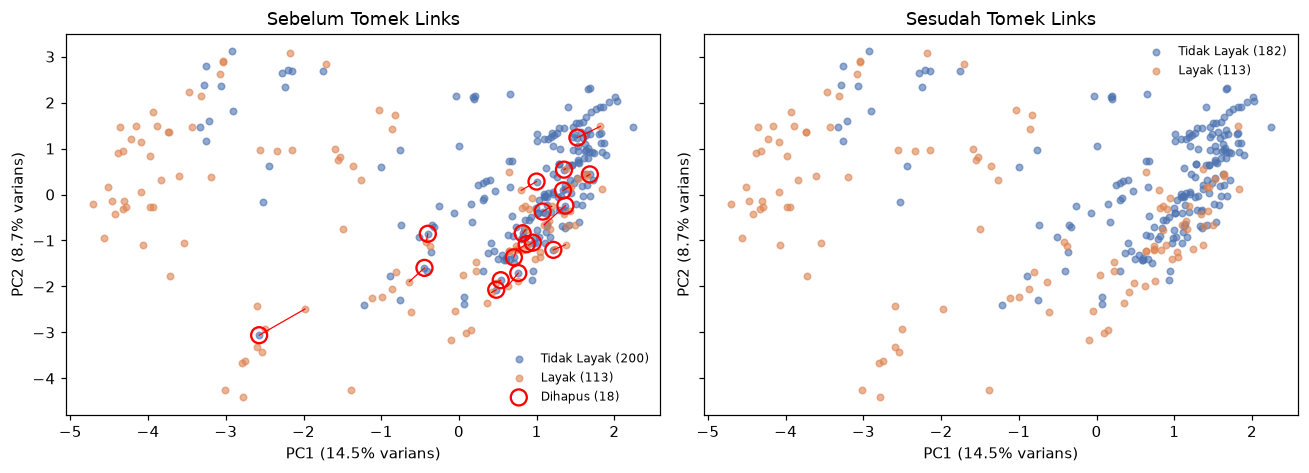

Kelas,Sebelum Tomek Links,Sesudah Tomek Links,Dihapus
Tidak Layak,200,182,18
Layak,113,113,0
Total,313,295,18


In [19]:
tabel(E8["t_tomek"], "pasangan_tomek_e2", "Pasangan Tomek Link pada Data Training Eksperimen 2")
simpan(viz.fig_tomek_links(E8["Xs"], E8["y_train"], E8["idx_hapus"], E8["pasangan"], RANDOM_STATE), "tomek_links_e2")
tabel(E8["t_hasil_tomek"], "hasil_tomek_e2", "Jumlah Data Training Sebelum dan Sesudah Tomek Links Eksperimen 2", desimal=0)

Kelas,Jumlah data,Bobot per data,Total bobot,Prior P(C)
Tidak Layak,182,"0,8104","147,5000","0,5000"
Layak,113,"1,3053","147,5000","0,5000"


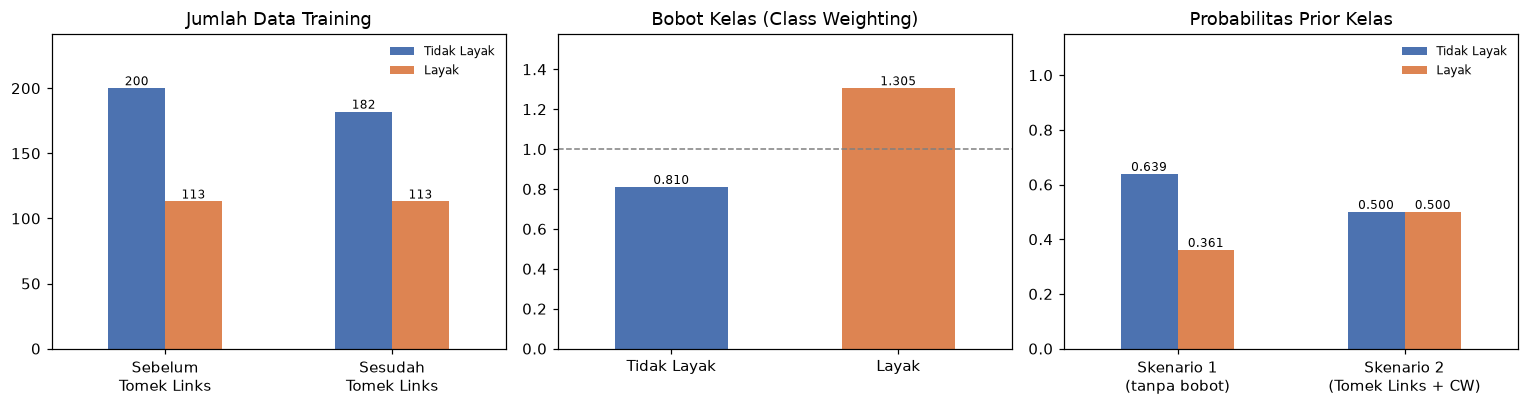

Atribut,Mean Tidak Layak,Varians Tidak Layak,Mean Layak,Varians Layak
Usia,"46,6099","177,4907","56,3274","233,9547"
Jenis Kelamin,"0,1209","0,1063","0,4159","0,2429"
Pekerjaan_Buruh Harian Lepas,"0,0934","0,0847","0,1150","0,1018"
Pekerjaan_Honorer,"0,0385","0,0370","0,0088","0,0088"
Pekerjaan_IRT,"0,0220","0,0215","0,2389","0,1818"
Pekerjaan_Karyawan Swasta,"0,1154","0,1021","0,0088","0,0088"
Pekerjaan_PNS,"0,1484","0,1263","0,0088","0,0088"
Pekerjaan_Pedagang,"0,0330","0,0319","0,0442","0,0423"
Pekerjaan_Pensiunan,"0,1044","0,0935","0,0088","0,0088"
Pekerjaan_Petani,"0,0330","0,0319","0,0885","0,0807"


No. data,Aktual,P(Tidak Layak | X),P(Layak | X),Prediksi,Keterangan
15,Layak,"0,9997","0,0003",Tidak Layak,Salah
82,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
320,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
101,Layak,"0,7617","0,2383",Tidak Layak,Salah
342,Layak,"0,0000","1,0000",Layak,Benar
325,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
134,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
338,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar
138,Layak,"0,0000","1,0000",Layak,Benar
40,Tidak Layak,"1,0000","0,0000",Tidak Layak,Benar


In [20]:
tabel(E8["t_prior2"], "bobot_prior_s2_e2", "Bobot Kelas dan Probabilitas Prior Skenario 2 Eksperimen 2")
simpan(viz.fig_class_weighting(E8["y_train"], E8["y_tl"], E8["bobot"], E8["prior1"], E8["prior2"])[0],
       "class_weighting_e2")
tabel(E8["t_param2"], "parameter_s2_e2", "Parameter Gaussian Berbobot Skenario 2 Eksperimen 2")
E8["t_pred2"].to_csv(TABEL_DIR / "lampiran_prediksi_s2_e2.csv", index=False, encoding="utf-8-sig")
tabel(E8["t_pred2"].head(10), "prediksi_s2_e2", "Cuplikan Hasil Prediksi Skenario 2 Eksperimen 2 (10 data testing)")

**e. Evaluasi (confusion matrix)**

Aktual \ Prediksi,Prediksi Tidak Layak,Prediksi Layak
Tidak Layak,49,1
Layak,15,14


Aktual \ Prediksi,Prediksi Tidak Layak,Prediksi Layak
Tidak Layak,49,1
Layak,14,15


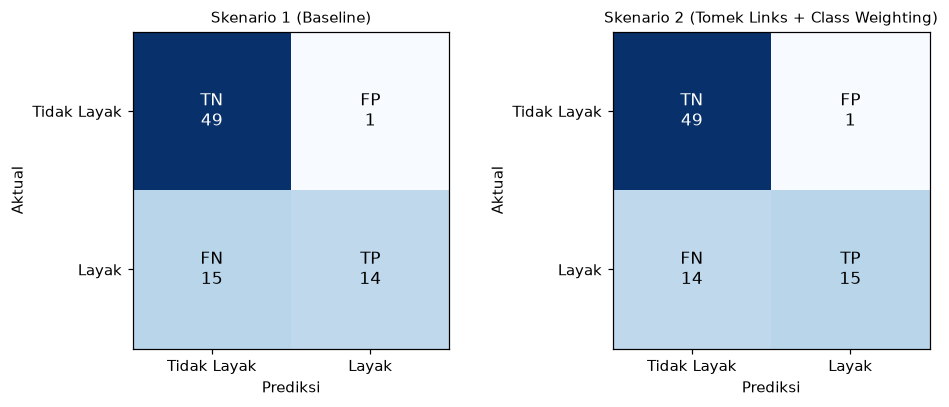

Metrik,Rumus,Substitusi,Hasil
Accuracy,(TP + TN) / (TP + TN + FP + FN),(14 + 49) / (14 + 49 + 1 + 15),"0,7975"
Precision,TP / (TP + FP),14 / (14 + 1),"0,9333"
Recall,TP / (TP + FN),14 / (14 + 15),"0,4828"
F1-Score,2 × (Precision × Recall) / (Precision + Recall),"2 × (0,9333 × 0,4828) / (0,9333 + 0,4828)","0,6364"
Specificity,TN / (TN + FP),49 / (49 + 1),"0,9800"


Metrik,Rumus,Substitusi,Hasil
Accuracy,(TP + TN) / (TP + TN + FP + FN),(15 + 49) / (15 + 49 + 1 + 14),"0,8101"
Precision,TP / (TP + FP),15 / (15 + 1),"0,9375"
Recall,TP / (TP + FN),15 / (15 + 14),"0,5172"
F1-Score,2 × (Precision × Recall) / (Precision + Recall),"2 × (0,9375 × 0,5172) / (0,9375 + 0,5172)","0,6667"
Specificity,TN / (TN + FP),49 / (49 + 1),"0,9800"


In [21]:
tabel(E8["t_cm1"], "cm_s1_e2", "Confusion Matrix Skenario 1 Eksperimen 2", desimal=0)
tabel(E8["t_cm2"], "cm_s2_e2", "Confusion Matrix Skenario 2 Eksperimen 2", desimal=0)
simpan(viz.fig_confusion_pair(E8["hasil_s1"], E8["hasil_s2"]), "confusion_matrix_e2")
tabel(E8["t_metrik1"], "metrik_s1_e2", "Perhitungan Metrik Evaluasi Skenario 1 Eksperimen 2")
tabel(E8["t_metrik2"], "metrik_s2_e2", "Perhitungan Metrik Evaluasi Skenario 2 Eksperimen 2")

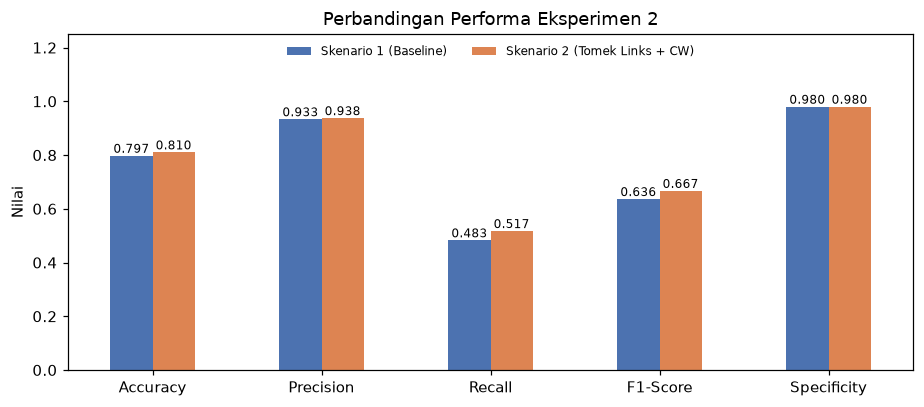

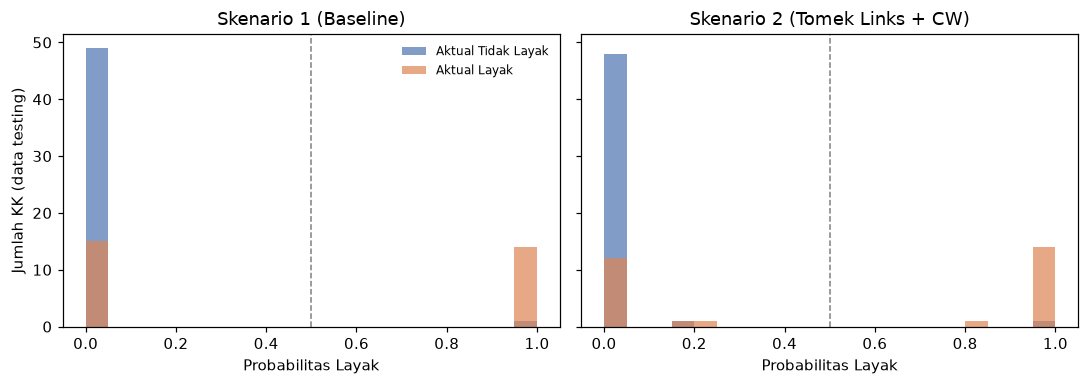

Skenario,TP,TN,FP,FN,Accuracy,Precision,Recall,F1-Score,Specificity
Skenario 1 (Baseline),14,49,1,15,"0,7975","0,9333","0,4828","0,6364","0,9800"
Skenario 2 (Tomek Links + CW),15,49,1,14,"0,8101","0,9375","0,5172","0,6667","0,9800"


In [22]:
perb = pd.DataFrame({"Skenario 1 (Baseline)": E8["hasil_s1"], "Skenario 2 (Tomek Links + CW)": E8["hasil_s2"]}).T
simpan(viz.fig_perbandingan_metrik(perb, "Perbandingan Performa Eksperimen 2"), "perbandingan_e2")
simpan(viz.fig_probabilitas(E8["y_test"], E8["proba1"], E8["proba2"]), "probabilitas_e2")
tabel(E8["t_perbandingan"], "perbandingan_e2", "Perbandingan Performa Skenario 1 dan Skenario 2 Eksperimen 2")

**f. Validasi dengan perhitungan manual** (Skenario 1)
1. Prior $P(C)$
2. Likelihood Gaussian $P(x_k|C)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\left(-\frac{(x_k-\mu)^2}{2\sigma^2}\right)$, dihitung dalam bentuk $\ln P(x_k|C)$ agar tidak terjadi *underflow*
3. Posterior $P(C|X) \propto P(C)\prod_k P(x_k|C)$

In [23]:
M8 = steps.perhitungan_manual(E8)
print(f"Data testing urutan ke-{M8['urutan'] + 1} (No. data {M8['no_data']}) | aktual: {M8['aktual']} | prediksi: {M8['prediksi']}")
tabel(M8["nilai_asli"], "data_manual_e2", "Data yang Dihitung pada Perhitungan Manual", desimal=0)
tabel(M8["t_likelihood"], "likelihood_manual_e2", "Mean, Varians, dan Likelihood Gaussian per Atribut")
tabel(M8["t_validasi"], "posterior_manual_e2", "Perbandingan Posterior Perhitungan Manual dan Sistem")

Data testing urutan ke-5 (No. data 342) | aktual: Layak | prediksi: Layak


Atribut,Nilai
Usia,70
Jenis Kelamin,L
Pekerjaan,Buruh Harian Lepas
Pendidikan terakhir,SMA
Status Pernikahan,Kawin
Tanggungan Keluarga,0
Status Tempat Tinggal,Milik Sendiri
Menerima Bantuan Lain,Ya


Atribut,Nilai x,Mean (TL),Varians (TL),P(x|C) (TL),ln P(x|C) (TL),Mean (L),Varians (L),P(x|C) (L),ln P(x|C) (L)
Usia,"70,0000","46,8000","170,1700","0,0063","-5,0688","56,3274","233,9547","0,0175","-4,0460"
Jenis Kelamin,"0,0000","0,1100","0,0979","1,1986","0,1812","0,4159","0,2429","0,5669","-0,5675"
Pekerjaan_Buruh Harian Lepas,"1,0000","0,1050","0,0940","0,0183","-3,9985","0,1150","0,1018","0,0267","-3,6228"
Pekerjaan_Honorer,"0,0000","0,0400","0,0384","1,9939","0,6901","0,0088","0,0088","4,2407","1,4447"
Pekerjaan_IRT,"0,0000","0,0200","0,0196","2,8206","1,0370","0,2389","0,1818","0,7996","-0,2236"
Pekerjaan_Karyawan Swasta,"0,0000","0,1050","0,0940","1,2272","0,2048","0,0088","0,0088","4,2407","1,4447"
Pekerjaan_PNS,"0,0000","0,1350","0,1168","1,0798","0,0768","0,0088","0,0088","4,2407","1,4447"
Pekerjaan_Pedagang,"0,0000","0,0300","0,0291","2,3027","0,8341","0,0442","0,0423","1,8956","0,6395"
Pekerjaan_Pensiunan,"0,0000","0,0950","0,0860","1,2910","0,2554","0,0088","0,0088","4,2407","1,4447"
Pekerjaan_Petani,"0,0000","0,0400","0,0384","1,9939","0,6901","0,0885","0,0807","1,3381","0,2912"


Kelas,ln P(C),Σ ln P(x|C),ln P(C) + Σ ln P(x|C),Posterior (manual),Posterior (sistem)
Tidak Layak,"-0,4479","-29,5156","-29,9635","0,0000","0,0000"
Layak,"-1,0188","-5,3086","-6,3274","1,0000","1,0000"


### 4.2.4 Perbandingan Kedua Eksperimen

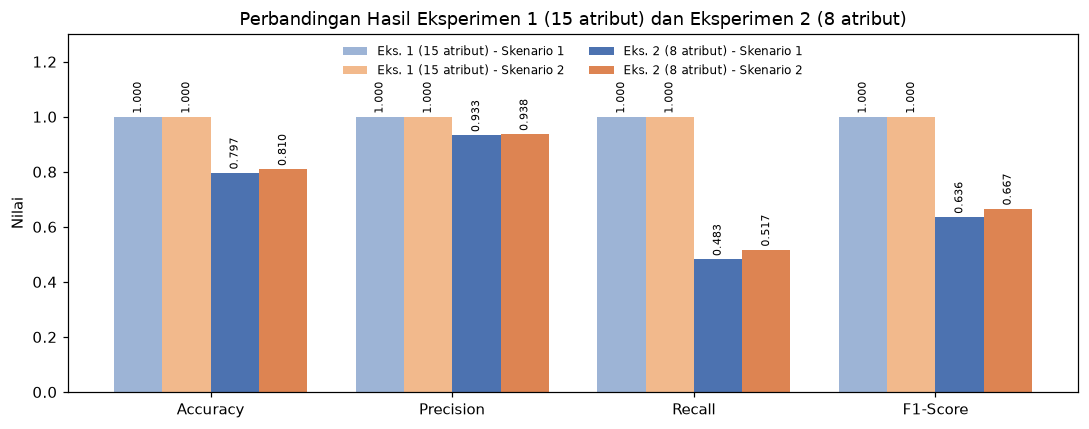

Eksperimen,Skenario,TP,TN,FP,FN,Accuracy,Precision,Recall,F1-Score,Specificity
Eksperimen 1 (15 atribut),Skenario 1,29,50,0,0,"1,0000","1,0000","1,0000","1,0000","1,0000"
Eksperimen 1 (15 atribut),Skenario 2,29,50,0,0,"1,0000","1,0000","1,0000","1,0000","1,0000"
Eksperimen 2 (8 atribut),Skenario 1,14,49,1,15,"0,7975","0,9333","0,4828","0,6364","0,9800"
Eksperimen 2 (8 atribut),Skenario 2,15,49,1,14,"0,8101","0,9375","0,5172","0,6667","0,9800"


In [24]:
rekap = steps.rekap_eksperimen(E15, E8)
simpan(viz.fig_rekap_eksperimen(rekap), "rekap_eksperimen")
tabel(rekap, "rekap_eksperimen", "Rekapitulasi Hasil Eksperimen 1 dan Eksperimen 2")

In [25]:
tabel(steps.pengujian_rasio_split(df, feature_cols=FEATURE_COLS_15), "rasio_split_e1",
      "Pengujian Rasio Pembagian Data Eksperimen 1 (15 atribut)")
tabel(steps.pengujian_rasio_split(df, feature_cols=FEATURE_COLS), "rasio_split_e2",
      "Pengujian Rasio Pembagian Data Eksperimen 2 (8 atribut)")

Rasio (training : testing),Data training,Data testing,Skenario,Data dihapus Tomek,TP,TN,FP,FN,Accuracy,Precision,Recall,F1-Score
70 : 30,274,118,Skenario 1,0,43,75,0,0,"1,0000","1,0000","1,0000","1,0000"
70 : 30,274,118,Skenario 2,3,43,75,0,0,"1,0000","1,0000","1,0000","1,0000"
75 : 25,294,98,Skenario 1,0,35,63,0,0,"1,0000","1,0000","1,0000","1,0000"
75 : 25,294,98,Skenario 2,3,35,63,0,0,"1,0000","1,0000","1,0000","1,0000"
80 : 20,313,79,Skenario 1,0,29,50,0,0,"1,0000","1,0000","1,0000","1,0000"
80 : 20,313,79,Skenario 2,3,29,50,0,0,"1,0000","1,0000","1,0000","1,0000"
85 : 15,333,59,Skenario 1,0,21,38,0,0,"1,0000","1,0000","1,0000","1,0000"
85 : 15,333,59,Skenario 2,4,21,38,0,0,"1,0000","1,0000","1,0000","1,0000"
90 : 10,352,40,Skenario 1,0,14,26,0,0,"1,0000","1,0000","1,0000","1,0000"
90 : 10,352,40,Skenario 2,4,14,26,0,0,"1,0000","1,0000","1,0000","1,0000"


Rasio (training : testing),Data training,Data testing,Skenario,Data dihapus Tomek,TP,TN,FP,FN,Accuracy,Precision,Recall,F1-Score
70 : 30,274,118,Skenario 1,0,22,73,2,21,"0,8051","0,9167","0,5116","0,6567"
70 : 30,274,118,Skenario 2,14,22,73,2,21,"0,8051","0,9167","0,5116","0,6567"
75 : 25,294,98,Skenario 1,0,17,61,2,18,"0,7959","0,8947","0,4857","0,6296"
75 : 25,294,98,Skenario 2,16,17,61,2,18,"0,7959","0,8947","0,4857","0,6296"
80 : 20,313,79,Skenario 1,0,14,49,1,15,"0,7975","0,9333","0,4828","0,6364"
80 : 20,313,79,Skenario 2,18,15,49,1,14,"0,8101","0,9375","0,5172","0,6667"
85 : 15,333,59,Skenario 1,0,10,37,1,11,"0,7966","0,9091","0,4762","0,6250"
85 : 15,333,59,Skenario 2,22,10,37,1,11,"0,7966","0,9091","0,4762","0,6250"
90 : 10,352,40,Skenario 1,0,7,25,1,7,"0,8000","0,8750","0,5000","0,6364"
90 : 10,352,40,Skenario 2,23,7,25,1,7,"0,8000","0,8750","0,5000","0,6364"


### 4.2.5 Representasi Pengetahuan (Eksperimen 2)

In [26]:
tabel(E8["t_proporsi"], "proporsi_atribut_e2", "Rata-rata/Proporsi Atribut per Kelas pada Data Training Eksperimen 2")
tabel(viz.tabel_profil_kelompok(df), "profil_kelompok", "Profil Rata-rata Atribut per Kelompok Seleksi", desimal=2)

Atribut,Jenis,Tidak Layak,Layak,Selisih (Layak - Tidak Layak)
Status Pernikahan_Kawin,Proporsi bernilai 1,"0,8600","0,5221","-0,3379"
Jenis Kelamin,Proporsi bernilai 1,"0,1100","0,4159","0,3059"
Status Pernikahan_Janda,Proporsi bernilai 1,"0,0650","0,3009","0,2359"
Pekerjaan_Tidak Bekerja,Proporsi bernilai 1,"0,0250","0,2478","0,2228"
Pekerjaan_IRT,Proporsi bernilai 1,"0,0200","0,2389","0,2189"
Menerima Bantuan Lain,Proporsi bernilai 1,"0,0150","0,1770","0,1620"
Pekerjaan_PNS,Proporsi bernilai 1,"0,1350","0,0088","-0,1262"
Pekerjaan_Wiraswasta,Proporsi bernilai 1,"0,2000","0,0973","-0,1027"
Pekerjaan_Karyawan Swasta,Proporsi bernilai 1,"0,1050","0,0088","-0,0962"
Pekerjaan_Pensiunan,Proporsi bernilai 1,"0,0950","0,0088","-0,0862"


Atribut (rata-rata / proporsi),Tidak Layak,"Layak, tidak menerima",Penerima BLT-DD
Terdaftar DTKS,"0,00","0,59","0,70"
KK miskin,"0,00","0,49","0,93"
Perempuan KK miskin,"0,00","0,26","0,59"
KK tunggal lansia,"0,00","0,17","0,63"
Kehilangan mata pencaharian,"0,00","0,05","0,04"
Anggota sakit kronis,"0,00","0,05","0,59"
Anggota disabilitas,"0,00","0,03","0,07"
Jumlah kriteria terpenuhi,"0,00","1,63","3,56"
Usia,"46,11","53,56","64,63"
Tanggungan Keluarga,"1,52","1,36","0,59"


## 4.3 Visualisasi Hasil Penelitian

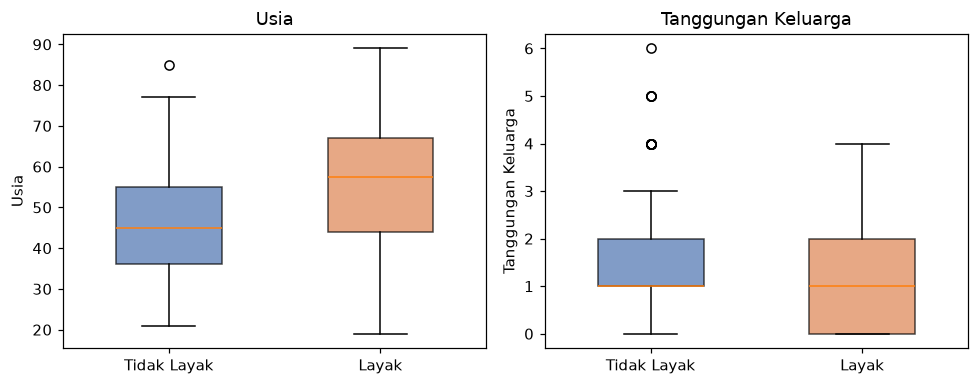

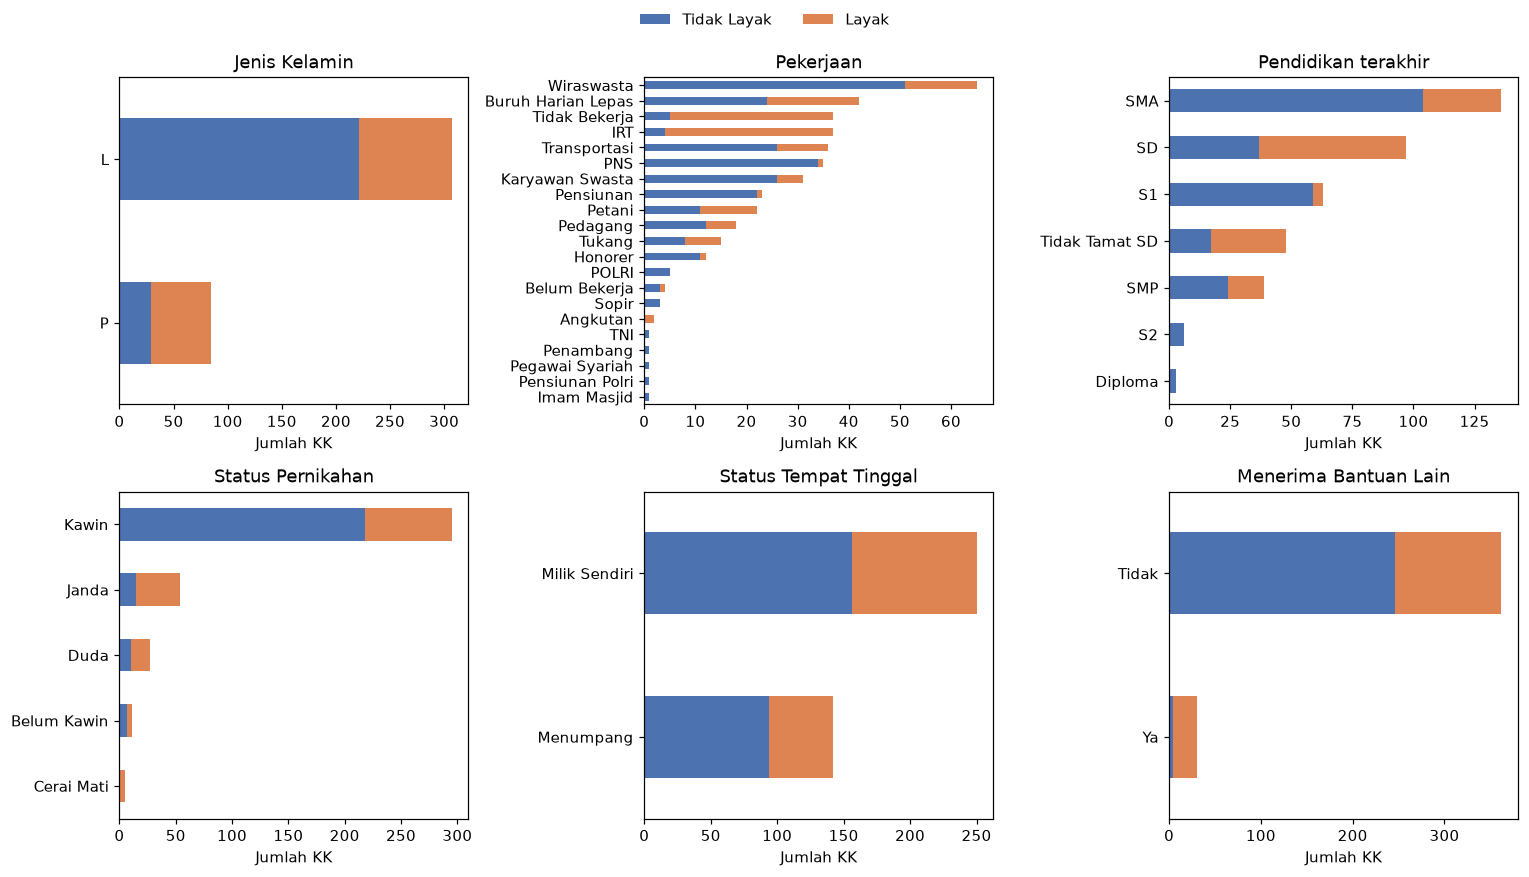

In [27]:
simpan(viz.fig_atribut_numerik(df), "atribut_numerik")
simpan(viz.fig_atribut_kategorikal(df), "atribut_kategorikal")

## Pendukung Bab V
Data untuk validasi di RapidMiner (Eksperimen 2). File `*_numerik.xlsx` berisi data hasil transformasi yang sama dengan sistem.

In [28]:
for p in steps.ekspor_rapidminer(E8["X_train_raw"], E8["X_test_raw"], E8["y_train"], E8["y_test"], E8["encoder"], RM_DIR):
    print(p.relative_to(BASE_DIR))
print("Hasil sistem yang harus dicocokkan (Eksperimen 2, Skenario 1):",
      {k: E8["hasil_s1"][k] for k in ("TP", "TN", "FP", "FN")})

outputs\rapidminer\data_training_asli.xlsx
outputs\rapidminer\data_training_numerik.xlsx
outputs\rapidminer\data_testing_asli.xlsx
outputs\rapidminer\data_testing_numerik.xlsx
Hasil sistem yang harus dicocokkan (Eksperimen 2, Skenario 1): {'TP': 14, 'TN': 49, 'FP': 1, 'FN': 15}


## Analisis Tambahan (Bahan Cadangan)
Pembanding algoritma lain pada 8 atribut — untuk menunjukkan batas akurasi yang dapat dicapai dari data sosial-ekonomi (validasi silang 10-fold, diulang 5 kali).

In [29]:
X8, y = df[FEATURE_COLS], encode_target(df[TARGET])
def cv_model(nama, tomek_cw=False):
    acc, rec, f1 = [], [], []
    for tr, te in RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=RANDOM_STATE).split(X8, y):
        enc = FeatureEncoder(feature_cols=FEATURE_COLS).fit(X8.iloc[tr])
        Xa, Xb = enc.transform(X8.iloc[tr]), enc.transform(X8.iloc[te])
        if nama == "Gaussian NB":
            p = train_scenario(Xa, y[tr], tomek_cw, tomek_cw).predict(Xb)
        else:
            sc = StandardScaler().fit(Xa)
            m = (LogisticRegression(max_iter=2000) if nama == "Logistic Regression"
                 else RandomForestClassifier(n_estimators=300, random_state=0))
            p = m.fit(sc.transform(Xa), y[tr]).predict(sc.transform(Xb))
        h = evaluate(y[te], p)
        acc.append(h["Accuracy"]); rec.append(h["Recall"]); f1.append(h["F1-Score"])
    return {"Akurasi": np.mean(acc), "Simpangan baku": np.std(acc), "Recall": np.mean(rec), "F1-Score": np.mean(f1)}

banding = pd.DataFrame([
    {"Model": "Gaussian NB (Skenario 1)", **cv_model("Gaussian NB")},
    {"Model": "Gaussian NB (Skenario 2)", **cv_model("Gaussian NB", True)},
    {"Model": "Logistic Regression", **cv_model("Logistic Regression")},
    {"Model": "Random Forest", **cv_model("Random Forest")},
])
tabel(banding, "cadangan_pembanding_algoritma", "Pembanding Algoritma pada 8 Atribut (Validasi Silang 10-Fold x 5)")

Model,Akurasi,Simpangan baku,Recall,F1-Score
Gaussian NB (Skenario 1),"0,7680","0,0914","0,7028","0,6908"
Gaussian NB (Skenario 2),"0,7959","0,0704","0,6510","0,6954"
Logistic Regression,"0,7935","0,0536","0,6119","0,6773"
Random Forest,"0,7745","0,0574","0,6144","0,6584"


## Menyimpan Model dan Rekap Tabel
Model Eksperimen 2 dipakai aplikasi Streamlit; model Eksperimen 1 disimpan sebagai pembanding.

In [30]:
from datetime import datetime
import sklearn

def paket(E):
    return {"feature_cols": E["feature_cols"], "encoder": E["encoder"],
            "models": {blt_dd.SCENARIO_NAMES["s1"]: E["s1"], blt_dd.SCENARIO_NAMES["s2"]: E["s2"]},
            "metrics": {blt_dd.SCENARIO_NAMES["s1"]: E["hasil_s1"], blt_dd.SCENARIO_NAMES["s2"]: E["hasil_s2"]}}

artefak = {
    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "sklearn_version": sklearn.__version__,
    **paket(E8),
    "n_data": int(len(df)), "n_train": int(len(E8["y_train"])), "n_test": int(len(E8["y_test"])),
    "class_counts": {"Layak": int(encode_target(df[TARGET]).sum()), "Tidak Layak": int((encode_target(df[TARGET]) == 0).sum())},
    "default_model": blt_dd.SCENARIO_NAMES["s2"],
    "analisis_15": paket(E15),
}
joblib.dump(artefak, MODEL_DIR / "model_blt_dd.joblib")

with pd.ExcelWriter(OUTPUT_DIR / "tabel_hasil.xlsx") as writer:
    pd.DataFrame([{"Sheet": k, "Judul Tabel": j} for k, (j, _) in DAFTAR_TABEL.items()]).to_excel(
        writer, sheet_name="Daftar Tabel", index=False)
    for kode, (judul, d) in DAFTAR_TABEL.items():
        d.to_excel(writer, sheet_name=kode[:31], index=False)
print("Model :", MODEL_DIR / "model_blt_dd.joblib")
print("Tabel :", OUTPUT_DIR / "tabel_hasil.xlsx", f"({len(DAFTAR_TABEL)} tabel)")
print("Gambar:", GAMBAR_DIR, f"({len(list(GAMBAR_DIR.glob('*.png')))} gambar)")

Model : C:\Users\FIQRI\Documents\JOKISKRIPSI\CS_1_data-mining\blt-dd-naive-bayes\models\model_blt_dd.joblib
Tabel : C:\Users\FIQRI\Documents\JOKISKRIPSI\CS_1_data-mining\blt-dd-naive-bayes\outputs\tabel_hasil.xlsx (54 tabel)
Gambar: C:\Users\FIQRI\Documents\JOKISKRIPSI\CS_1_data-mining\blt-dd-naive-bayes\outputs\gambar (17 gambar)
